# Kakhovka dam breach — flood detection, Kherson (June 2023)

Runs the `flood_detection` UDP (Sentinel-1 VV water mask over a Sentinel-2 NIR background) twice on CDSE: once before the dam breach (6 June 2023) and once during the flooding, then plots the two results side by side.

Scenes picked up by each window (openEO end dates are exclusive):

| Run | Window | Sentinel-1 GRD | Sentinel-2 L2A |
|---|---|---|---|
| Pre-flood | 2023-06-02 → 2023-06-04 | 2023-06-02 (ascending, full bbox) | 2023-06-03 (8% cloud) |
| During flood | 2023-06-03 → 2023-06-10 | 2023-06-09 (ascending, east ~68%) + 2023-06-06 (west edge) | 2023-06-03 |

In [1]:
from pathlib import Path

import openeo

connection = openeo.connect("https://openeo.dataspace.copernicus.eu/").authenticate_oidc()

Authenticated using refresh token.


In [2]:
# Bounding box and temporal extent
shape = {"west": 31.900898, "south": 46.333770, "east": 32.777495, "north": 46.773495}
pre_flood_start_date, pre_flood_end_date = ["2023-06-02", "2023-06-04"]
flood_start_date, flood_end_date = ["2023-06-03", "2023-06-10"]

public_url = "https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/9f17ad672fa4227806ec42b3d9c59b172318d998/algorithm_catalog/developmentseed/flood_detection/openeo_udp/flood_detection.json"

# The process id must match the "id" in the UDP JSON at public_url, for both runs.
process_id = "flood_detection"

pre_flood_output = Path("flood_detection_kherson_preflood.tif")
flood_output = Path("flood_detection_kherson_flood.tif")

In [3]:
pre_flood_kherson = connection.datacube_from_process(
    process_id,
    namespace=public_url,
    time=[pre_flood_start_date, pre_flood_end_date],
    bounding_box=shape,
)

flood_kherson = connection.datacube_from_process(
    process_id,
    namespace=public_url,
    time=[flood_start_date, flood_end_date],
    bounding_box=shape,
)

## Pre-flood

In [4]:
pre_flood_job = pre_flood_kherson.create_job(
    title=f"Pre-flood detection for {pre_flood_start_date} to {pre_flood_end_date}",
    out_format="GTiff",
)
pre_flood_job.start_and_wait()

0:00:00 Job 'j-261027173454485f895ca2a5ef1b699a': send 'start'
0:00:02 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:07 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:13 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:21 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:31 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:44 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:00:59 Job 'j-261027173454485f895ca2a5ef1b699a': queued (progress 0%)
0:01:18 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:01:43 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:02:13 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:02:50 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:03:37 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:04:35 Job 'j-261027173454485f895ca2a5ef1b699a': running (progress N/A)
0:

<BatchJob job_id='j-261027173454485f895ca2a5ef1b699a'>

In [7]:
# Each result is a single GeoTIFF (~360 MB). If the download breaks, rerun only
# this cell; the job does not need to be resubmitted.
pre_flood_job.get_results().download_file(pre_flood_output)

PosixPath('flood_detection_kherson_preflood.tif')

## During flood

In [8]:
flood_job = flood_kherson.create_job(
    title=f"Flood detection for {flood_start_date} to {flood_end_date}",
    out_format="GTiff",
)
flood_job.start_and_wait()

0:00:00 Job 'j-261027175026433ead0e3116e921d3b3': send 'start'
0:00:03 Job 'j-261027175026433ead0e3116e921d3b3': created (progress 0%)
0:00:08 Job 'j-261027175026433ead0e3116e921d3b3': queued (progress 0%)
0:00:14 Job 'j-261027175026433ead0e3116e921d3b3': queued (progress 0%)
0:00:22 Job 'j-261027175026433ead0e3116e921d3b3': queued (progress 0%)
0:00:32 Job 'j-261027175026433ead0e3116e921d3b3': queued (progress 0%)
0:00:45 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:01:00 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:01:19 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:01:44 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:02:14 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:02:51 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:03:38 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/A)
0:04:36 Job 'j-261027175026433ead0e3116e921d3b3': running (progress N/

<BatchJob job_id='j-261027175026433ead0e3116e921d3b3'>

In [9]:
flood_job.get_results().download_file(flood_output)

PosixPath('flood_detection_kherson_flood.tif')

## Pre-flood vs during flood

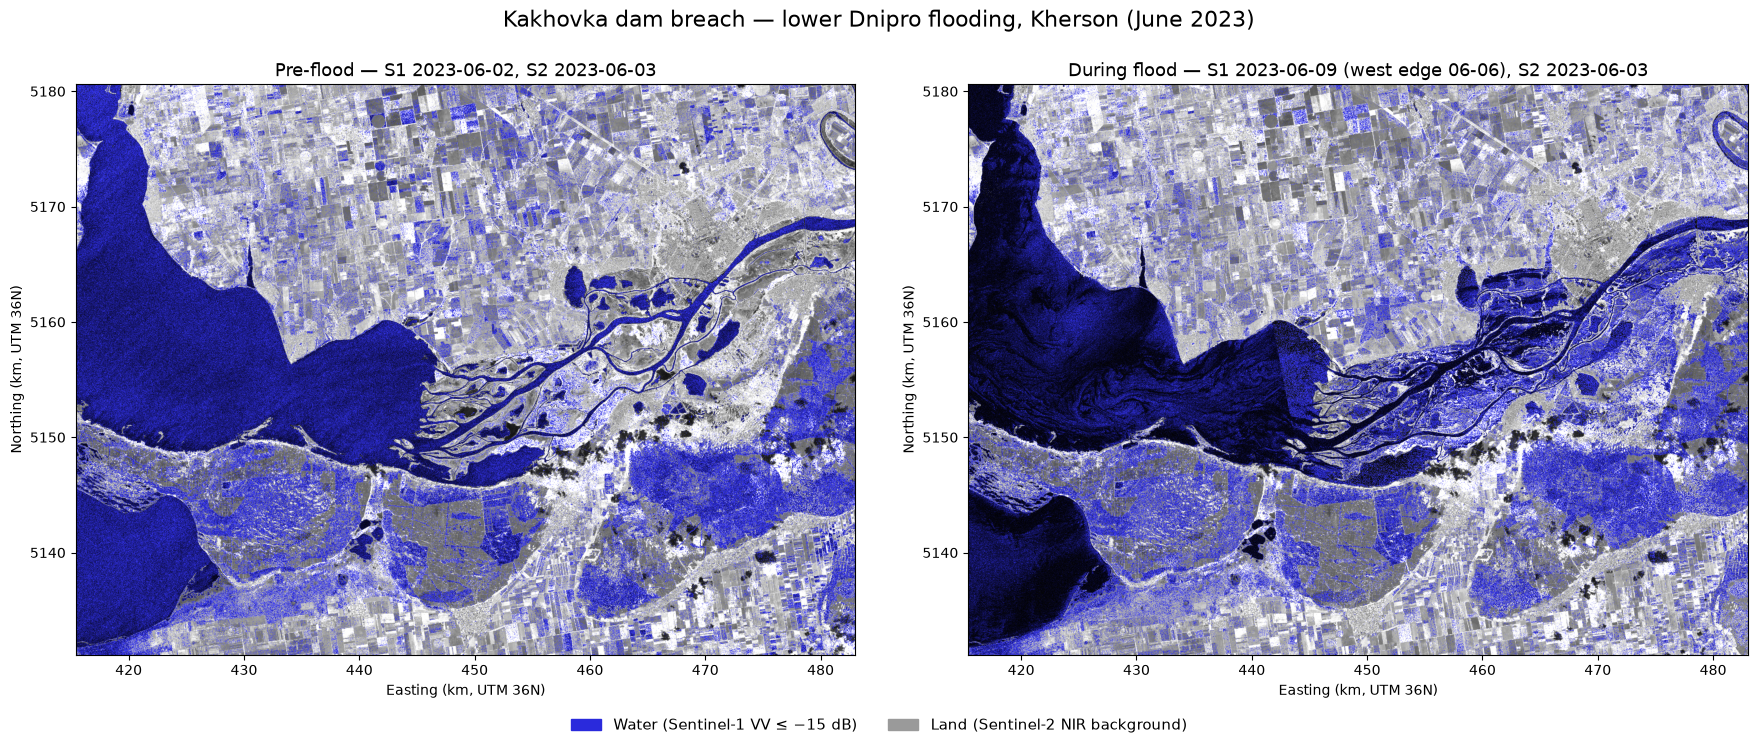

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Patch

# Read at 1/3 resolution: a full 10 m scene is ~6800x5000 px per panel.
DOWNSAMPLE = 3


def read_rgb(path):
    """Read a 3-band flood_detection GeoTIFF as an (H, W, 3) 0-1 array plus its extent in km."""
    with rasterio.open(path) as src:
        out_shape = (3, src.height // DOWNSAMPLE, src.width // DOWNSAMPLE)
        data = src.read(out_shape=out_shape)
        b = src.bounds
    # The UDP output is already display-scaled; only clip to 0-1.
    rgb = np.clip(np.nan_to_num(np.moveaxis(data, 0, -1)), 0, 1)
    extent = [b.left / 1000, b.right / 1000, b.bottom / 1000, b.top / 1000]
    return rgb, extent


fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), squeeze=False)

for ax, path, title in (
    (axes[0, 0], pre_flood_output, "Pre-flood — S1 2023-06-02, S2 2023-06-03"),
    (axes[0, 1], flood_output, "During flood — S1 2023-06-09 (west edge 06-06), S2 2023-06-03"),
):
    rgb, extent = read_rgb(path)
    ax.imshow(rgb, extent=extent)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Easting (km, UTM 36N)")
    ax.set_ylabel("Northing (km, UTM 36N)")

fig.legend(
    handles=[
        Patch(color="#2a2adc", label="Water (Sentinel-1 VV ≤ −15 dB)"),
        Patch(color="#9a9a9a", label="Land (Sentinel-2 NIR background)"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=11,
)
fig.suptitle("Kakhovka dam breach — lower Dnipro flooding, Kherson (June 2023)", fontsize=16)
fig.tight_layout(rect=(0, 0.1, 1, 0.95))
fig.savefig("flood_detection_kherson_comparison.png", dpi=200)
plt.show()